# 01 - Phân Tích Khám Phá Dữ Liệu (EDA) - MovieLens 100K

**Dự án:** Hệ thống gợi ý phim / bài hát theo sở thích ứng dụng Trí tuệ nhân tạo (AI Recommendation System).  
**Học phần:** Trí tuệ nhân tạo (K5)  
**Dataset:** MovieLens 100K (GroupLens Research - University of Minnesota)  

---

### Mục tiêu phân tích:
1. Đánh giá tính toàn vẹn, phân bố và đặc tính thống kê của MovieLens 100K.
2. Đo lường độ thưa (sparsity) của ma trận tương tác User-Item.
3. Phân tích hiện tượng phân bố đuôi dài (Long-Tail Distribution) của phim và người dùng.
4. Đánh giá tác động của các đặc trưng dữ liệu đến việc thiết kế và lựa chọn **10 mô hình gợi ý** trong các giai đoạn tiếp theo.


In [1]:
import sys
from pathlib import Path

# Thêm thư mục gốc vào sys.path để import module từ src
REPO_ROOT = Path("..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from src.data_loader import load_movielens_100k, validate_movielens_data, GENRE_NAMES

# Cấu hình thẩm mỹ hiển thị biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
print("Thư viện đã được tải thành công!")


Thư viện đã được tải thành công!


## 1. Nạp và Xác Thực Dữ Liệu Gốc

In [2]:
ratings, movies, users = load_movielens_100k(data_dir=REPO_ROOT / "data" / "raw" / "ml-100k")
val_report = validate_movielens_data(ratings, movies, users)

print(f"Tổng số bản ghi đánh giá (ratings): {len(ratings):,}")
print(f"Tổng số người dùng (users):          {len(users):,}")
print(f"Tổng số bộ phim (movies):            {len(movies):,}")
print(f"Độ thưa ma trận tương tác:          {val_report['matrix_sparsity_percent']}%")


2026-10-27 17:07:46,693 - INFO - Successfully loaded ratings: 100000 rows.


2026-10-27 17:07:46,698 - INFO - Successfully loaded movies: 1682 items.


2026-10-27 17:07:46,702 - INFO - Successfully loaded users: 943 users.


2026-10-27 17:07:46,721 - INFO - Validation passed successfully: {'is_valid': True, 'num_ratings': 100000, 'num_users': 943, 'num_movies': 1682, 'min_rating': 1.0, 'max_rating': 5.0, 'duplicated_interactions': 0, 'user_nulls': 0, 'movie_nulls': 0, 'rating_nulls': 0, 'matrix_sparsity_percent': 93.6953}


Tổng số bản ghi đánh giá (ratings): 100,000
Tổng số người dùng (users):          943
Tổng số bộ phim (movies):            1,682
Độ thưa ma trận tương tác:          93.6953%


## 2. Phân Bố Điểm Đánh Giá (Ratings 1 đến 5 sao)

,Số lượng,Tỷ lệ (%)
rating,,
1,6110,6.11
2,11370,11.37
3,27145,27.15
4,34174,34.17
5,21201,21.20


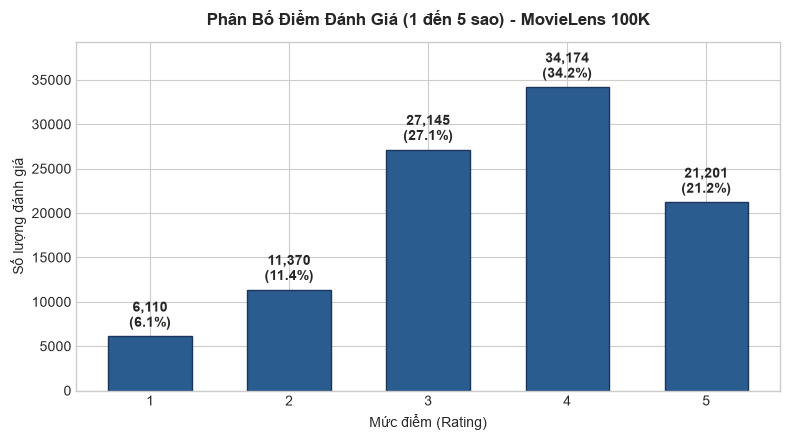

In [3]:
rating_counts = ratings['rating'].value_counts().sort_index()
rating_pct = (rating_counts / len(ratings)) * 100

dist_df = pd.DataFrame({
    'Số lượng': rating_counts,
    'Tỷ lệ (%)': rating_pct.round(2)
})
display(dist_df)

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(rating_counts.index, rating_counts.values, color='#2b5c8f', edgecolor='#1a365d', width=0.6)
for bar in bars:
    h = bar.get_height()
    pct = (h / len(ratings)) * 100
    ax.annotate(f"{h:,}\n({pct:.1f}%)", xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 4), textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_title("Phân Bố Điểm Đánh Giá (1 đến 5 sao) - MovieLens 100K", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Mức điểm (Rating)", fontsize=10)
ax.set_ylabel("Số lượng đánh giá", fontsize=10)
ax.set_ylim(0, max(rating_counts.values) * 1.15)
plt.tight_layout()
plt.show()


## 3. Hoạt Động Của Người Dùng (Ratings per User)

Số lượt đánh giá tối thiểu của 1 user: 20
Số lượt đánh giá trung bình của 1 user: 106.04
Trung vị số đánh giá:                  65.0
Số lượt đánh giá tối đa của 1 user:     737


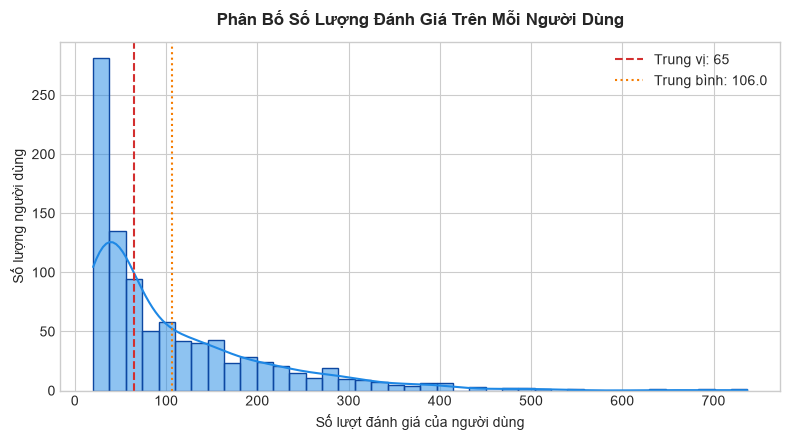

In [4]:
user_activity = ratings.groupby('user_id').size()
print(f"Số lượt đánh giá tối thiểu của 1 user: {user_activity.min()}")
print(f"Số lượt đánh giá trung bình của 1 user: {user_activity.mean():.2f}")
print(f"Trung vị số đánh giá:                  {user_activity.median()}")
print(f"Số lượt đánh giá tối đa của 1 user:     {user_activity.max()}")

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(user_activity, bins=40, kde=True, color='#1e88e5', edgecolor='#0d47a1', ax=ax)
ax.axvline(user_activity.median(), color='#d32f2f', linestyle='--', label=f"Trung vị: {int(user_activity.median())}")
ax.axvline(user_activity.mean(), color='#f57c00', linestyle=':', label=f"Trung bình: {user_activity.mean():.1f}")
ax.set_title("Phân Bố Số Lượng Đánh Giá Trên Mỗi Người Dùng", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Số lượt đánh giá của người dùng", fontsize=10)
ax.set_ylabel("Số lượng người dùng", fontsize=10)
ax.legend()
plt.tight_layout()
plt.show()


## 4. Hiện Tượng Đuôi Dài (Long-Tail Distribution)

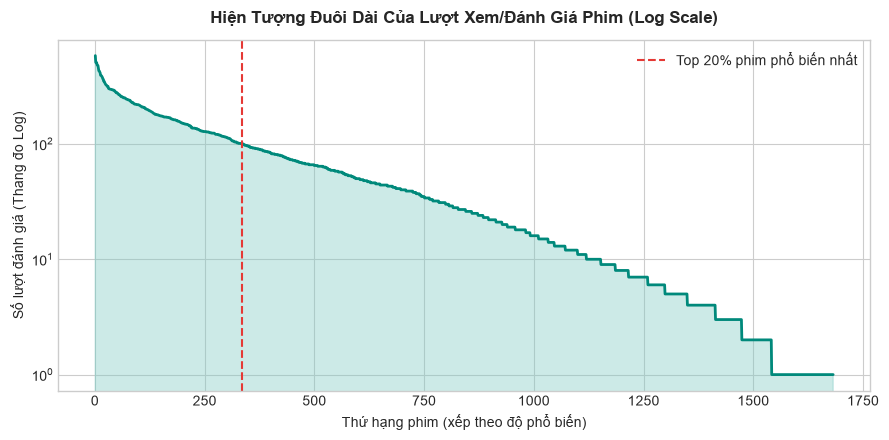

In [5]:
movie_popularity = ratings.groupby('movie_id').size().sort_values(ascending=False).values

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(range(1, len(movie_popularity) + 1), movie_popularity, color='#00897b', linewidth=2)
ax.fill_between(range(1, len(movie_popularity) + 1), movie_popularity, color='#80cbc4', alpha=0.4)
ax.axvline(x=int(len(movie_popularity) * 0.2), color='#e53935', linestyle='--', label="Top 20% phim phổ biến nhất")
ax.set_title("Hiện Tượng Đuôi Dài Của Lượt Xem/Đánh Giá Phim (Log Scale)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Thứ hạng phim (xếp theo độ phổ biến)", fontsize=10)
ax.set_ylabel("Số lượt đánh giá (Thang đo Log)", fontsize=10)
ax.set_yscale('log')
ax.legend()
plt.tight_layout()
plt.show()


## 5. Top 10 Phim Phổ Biến Nhất & Top 10 Phim Điểm Cao Nhất

In [6]:
# Top 10 phổ biến nhất
top10_pop = (
    ratings.groupby('movie_id')
    .size()
    .reset_index(name='luot_danh_gia')
    .merge(movies[['movie_id', 'title']], on='movie_id')
    .sort_values('luot_danh_gia', ascending=False)
    .head(10)
)
print("=== TOP 10 PHIM CÓ NHIỀU ĐÁNH GIÁ NHẤT ===")
display(top10_pop[['movie_id', 'title', 'luot_danh_gia']])

# Top 10 điểm trung bình cao nhất (Ngưỡng tối thiểu 100 đánh giá để tránh thiên lệch mẫu nhỏ)
movie_stats = (
    ratings.groupby('movie_id')
    .agg(diem_tb=('rating', 'mean'), so_danh_gia=('rating', 'count'))
    .reset_index()
    .merge(movies[['movie_id', 'title']], on='movie_id')
)
top10_high = (
    movie_stats[movie_stats['so_danh_gia'] >= 100]
    .sort_values('diem_tb', ascending=False)
    .head(10)
)
print("\n=== TOP 10 PHIM ĐIỂM TRUNG BÌNH CAO NHẤT (>= 100 ĐÁNH GIÁ) ===")
display(top10_high[['movie_id', 'title', 'diem_tb', 'so_danh_gia']])


=== TOP 10 PHIM CÓ NHIỀU ĐÁNH GIÁ NHẤT ===


,movie_id,title,luot_danh_gia
49,50,Star Wars (1977),583
257,258,Contact (1997),509
99,100,Fargo (1996),508
180,181,Return of the Jedi (1983),507
293,294,Liar Liar (1997),485
285,286,"English Patient, The (1996)",481
287,288,Scream (1996),478
0,1,Toy Story (1995),452
299,300,Air Force One (1997),431
120,121,Independence Day (ID4) (1996),429



=== TOP 10 PHIM ĐIỂM TRUNG BÌNH CAO NHẤT (>= 100 ĐÁNH GIÁ) ===


,movie_id,title,diem_tb,so_danh_gia
407,408,"Close Shave, A (1995)",4.491071,112
317,318,Schindler's List (1993),4.466443,298
168,169,"Wrong Trousers, The (1993)",4.466102,118
482,483,Casablanca (1942),4.456790,243
63,64,"Shawshank Redemption, The (1994)",4.445230,283
602,603,Rear Window (1954),4.387560,209
11,12,"Usual Suspects, The (1995)",4.385768,267
49,50,Star Wars (1977),4.358491,583
177,178,12 Angry Men (1957),4.344000,125
133,134,Citizen Kane (1941),4.292929,198


## 6. Phân Bố Thể Loại Phim (19 Thể Loại)

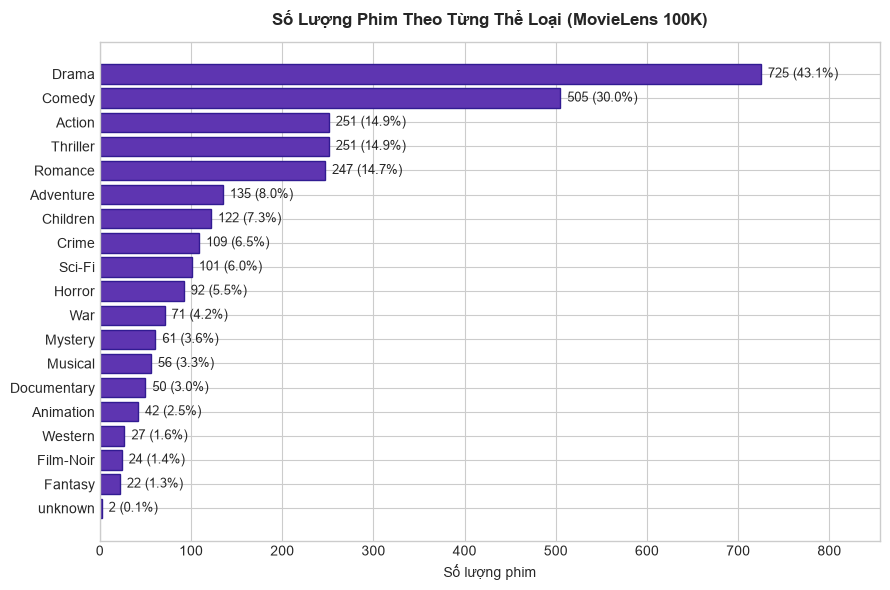

In [7]:
genre_totals = movies[GENRE_NAMES].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(genre_totals.index[::-1], genre_totals.values[::-1], color='#5e35b1', edgecolor='#311b92')
for bar in bars:
    w = bar.get_width()
    pct = (w / len(movies)) * 100
    ax.annotate(f"{w:,} ({pct:.1f}%)", xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(5, 0), textcoords="offset points", ha='left', va='center', fontsize=9)
ax.set_title("Số Lượng Phim Theo Từng Thể Loại (MovieLens 100K)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Số lượng phim", fontsize=10)
ax.set_xlim(0, max(genre_totals.values) * 1.18)
plt.tight_layout()
plt.show()


## 7. Phân Tích Độ Thưa Ma Trận (Matrix Sparsity)

In [8]:
total_cells = len(users) * len(movies)
observed_ratings = len(ratings)
unobserved_cells = total_cells - observed_ratings
sparsity = (unobserved_cells / total_cells) * 100

print(f"Tổng số ô trong ma trận User-Item ({len(users)} x {len(movies)}): {total_cells:,}")
print(f"Số ô đã có đánh giá (Observed):                       {observed_ratings:,} ({100 - sparsity:.2f}%)")
print(f"Số ô trống / chưa đánh giá (Unobserved):              {unobserved_cells:,} ({sparsity:.2f}%)")


Tổng số ô trong ma trận User-Item (943 x 1682): 1,586,126
Số ô đã có đánh giá (Observed):                       100,000 (6.30%)
Số ô trống / chưa đánh giá (Unobserved):              1,486,126 (93.70%)


## 8. Hoạt Động Đánh Giá Theo Dòng Thời Gian

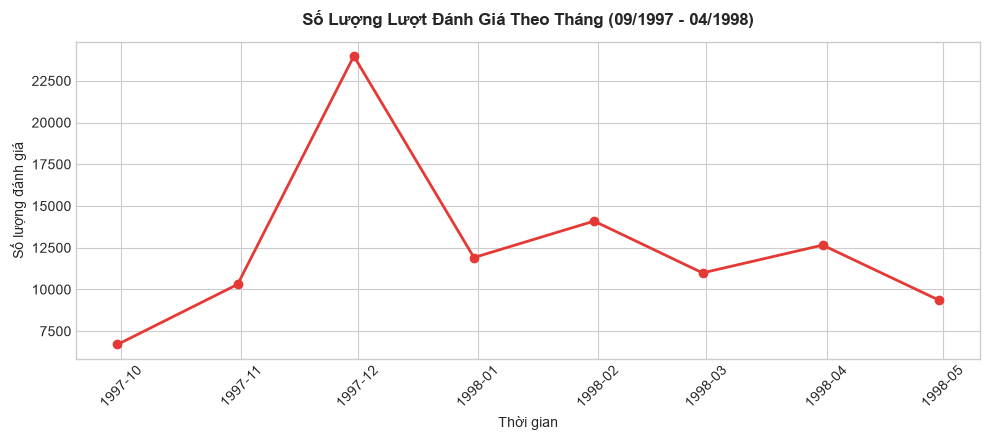

In [9]:
ratings_time = ratings.copy()
ratings_time['date'] = pd.to_datetime(ratings_time['timestamp'], unit='s')
monthly_ratings = ratings_time.set_index('date').resample('ME').size()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly_ratings.index, monthly_ratings.values, color='#e53935', marker='o', linewidth=2)
ax.set_title("Số Lượng Lượt Đánh Giá Theo Tháng (09/1997 - 04/1998)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Thời gian", fontsize=10)
ax.set_ylabel("Số lượng đánh giá", fontsize=10)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 9. Nhận Xét Chuyên Sâu & Tác Động Đến Thuật Toán Gợi Ý

Qua quá trình thực nghiệm khám phá dữ liệu (EDA), chúng tôi rút ra các kết luận quan trọng cho bài toán gợi ý:

1. **Độ lệch phân bố điểm số (Rating Bias):**
   - Khoảng 55.4% tổng số lượt đánh giá rơi vào điểm 4 và 5 sao. Điểm 1 và 2 sao chỉ chiếm chưa đầy 18%.
   - *Tác động:* Cần thiết lập mô hình có thành phần điều chỉnh độ lệch bias (Baseline Estimates, KNNBaseline, SVD with Biases) để tránh dự đoán thiên lệch cho người dùng khó tính hoặc dễ tính.

2. **Hiện tượng đuôi dài (Long-Tail Distribution):**
   - Khoảng 20% phim phổ biến chiếm tới gần 80% tổng số lượt đánh giá (tiêu biểu như *Star Wars (1977)*, *Contact (1997)*, *Fargo (1996)*). Hàng trăm bộ phim khác chỉ có từ 1 đến 5 đánh giá.
   - *Tác động:* Các mô hình Baseline dựa trên độ phổ biến (Popularity Recommender) sẽ đạt độ chính xác khá tốt trên toàn bộ tập dữ liệu nhưng thiếu tính đa dạng (Diversity) và không gợi ý được các phim ngách (Serendipity). Các mô hình Lọc cộng tác (CF) cần áp dụng kỹ thuật co cụm hoặc lọc dựa trên nội dung (Content-Based) để giải quyết vấn đề Cold-Start cho item ít tương tác.

3. **Độ thưa ma trận cao (93.70% Sparsity):**
   - Mặc dù mỗi người dùng trong MovieLens 100K có tối thiểu 20 lượt đánh giá, mật độ ma trận vẫn chỉ đạt khoảng 6.30%.
   - *Tác động:* Biểu diễn dạng ma trận dày (Dense Matrix) sẽ gây lãng phí bộ nhớ khổng lồ. Bắt buộc phải sử dụng biểu diễn ma trận thưa (`scipy.sparse.csr_matrix`). Các thuật toán phân rã ma trận như **SVD**, **SVD++**, **NMF** và mạng nơ-ron **NCF** sẽ phát huy ưu thế vượt trội so với KNN truyền thống khi không gian chiều bị thiếu hụt nghiêm trọng.

4. **Định nghĩa tương tác tích cực (Positive Interaction) cho bài toán Top-N:**
   - Với thang điểm 1-5 sao, việc người dùng đánh giá 1-3 sao thường mang ý nghĩa không hài lòng hoặc trung tính.
   - *Quyết định thiết kế:* Định nghĩa **Rating $\ge$ 4** là tương tác phù hợp (Relevant Item) để đánh giá các độ đo Top-N Ranking (Precision@K, Recall@K, NDCG@K, Hit Rate@K).
